## **도구(툴) 활용**

> **한눈에 보기**
> - 함수 + 명세로 도구 만들기 → `function_call` 실행 → `function_call_output`으로 결과 전달
> - 실시간 날씨 에이전트: 질문 하나에 도시 두 개면 도구를 두 번 요청한다
> - 정리 문서: [도구호출.md](도구호출.md)

> 한화내일아카데미 10월 12일 수업 실습 노트북입니다. 이날부터 강사님이 직접 만든 자료로 수업이 진행됐습니다.
> - 강의 슬라이드 이미지(강사님이 AI로 만든 그림 등)는 강사님 허락을 받아 그대로 넣었습니다.
> - **📝 정리** 셀은 실행 결과를 보고 직접 정리한 내용입니다.
> - API 키는 코드에 쓰지 않고 환경변수(`OPENAI_API_KEY`, `GEMINI_API_KEY`)에서 읽습니다.

**LLM에 도구(툴)가 필요한 이유**는 4가지로 정리됩니다.

1. 모르는 것 — 지식의 시간적 한계
학습 시점 이후의 정보(오늘 날씨, 최신 뉴스, 우리 회사 내부 문서)는 알 수 없습니다. → 검색 툴, RAG로 보완

2. 못하는 것 — 정확한 계산/결정적 로직
LLM은 다음 토큰을 확률적으로 예측하는 방식이라, 정밀한 수치 계산이나 복잡한 로직은 틀리기 쉽습니다. → 계산기, 코드 실행에 위임

3. 할 수 없는 것 — 실제 행동
텍스트를 생성할 뿐, 이메일을 보내거나 DB에 쓰거나 캘린더에 등록하는 건 LLM 혼자서는 불가능합니다. → API 호출로 실행을 대신

4. 믿을 수 없는 것 — 환각(hallucination)
모르는 걸 그럴듯하게 지어낼 수 있습니다. → 외부 도구로 근거를 확인하고 답변에 반영

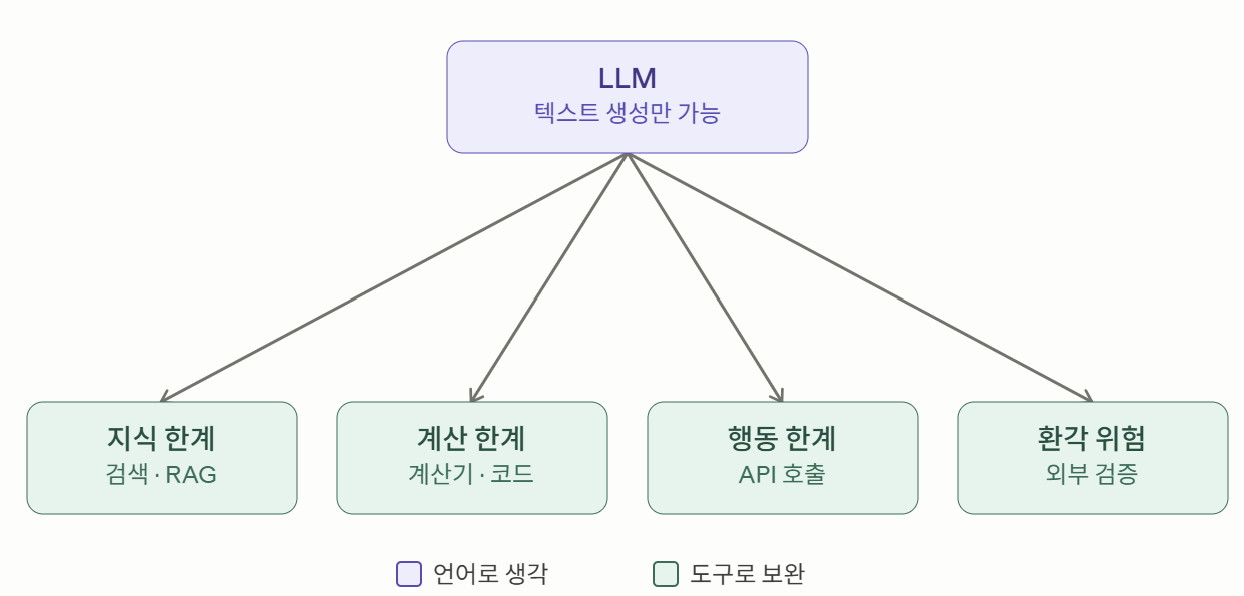

**LLM은 "언어로 생각하는 두뇌"고 도구는 "세상과 연결되는 손과 눈"**

In [1]:
from openai import OpenAI

client = OpenAI()
# 최신 Responses API 호출 방식
response = client.responses.create(
    model="gpt-4o-mini",    
    input="지금 몇 시야? 그리고 오늘 날짜도 알려줘.",
    max_output_tokens=500,
    temperature=0.7
)
print(response.output_text)

지금 몇 시인지와 오늘 날짜는 제가 확인할 수 없어요. 하지만 당신의 기기에서 시계나 달력을 확인하면 정확한 시간을 알 수 있을 거예요. 도움이 필요하면 언제든지 말씀해 주세요!


**📝 정리** — 도구 없이 시간과 날짜를 물으면 모델은 알 수 없다고 답한다. 학습 시점 이후의 실시간 정보는 모르기 때문이다.

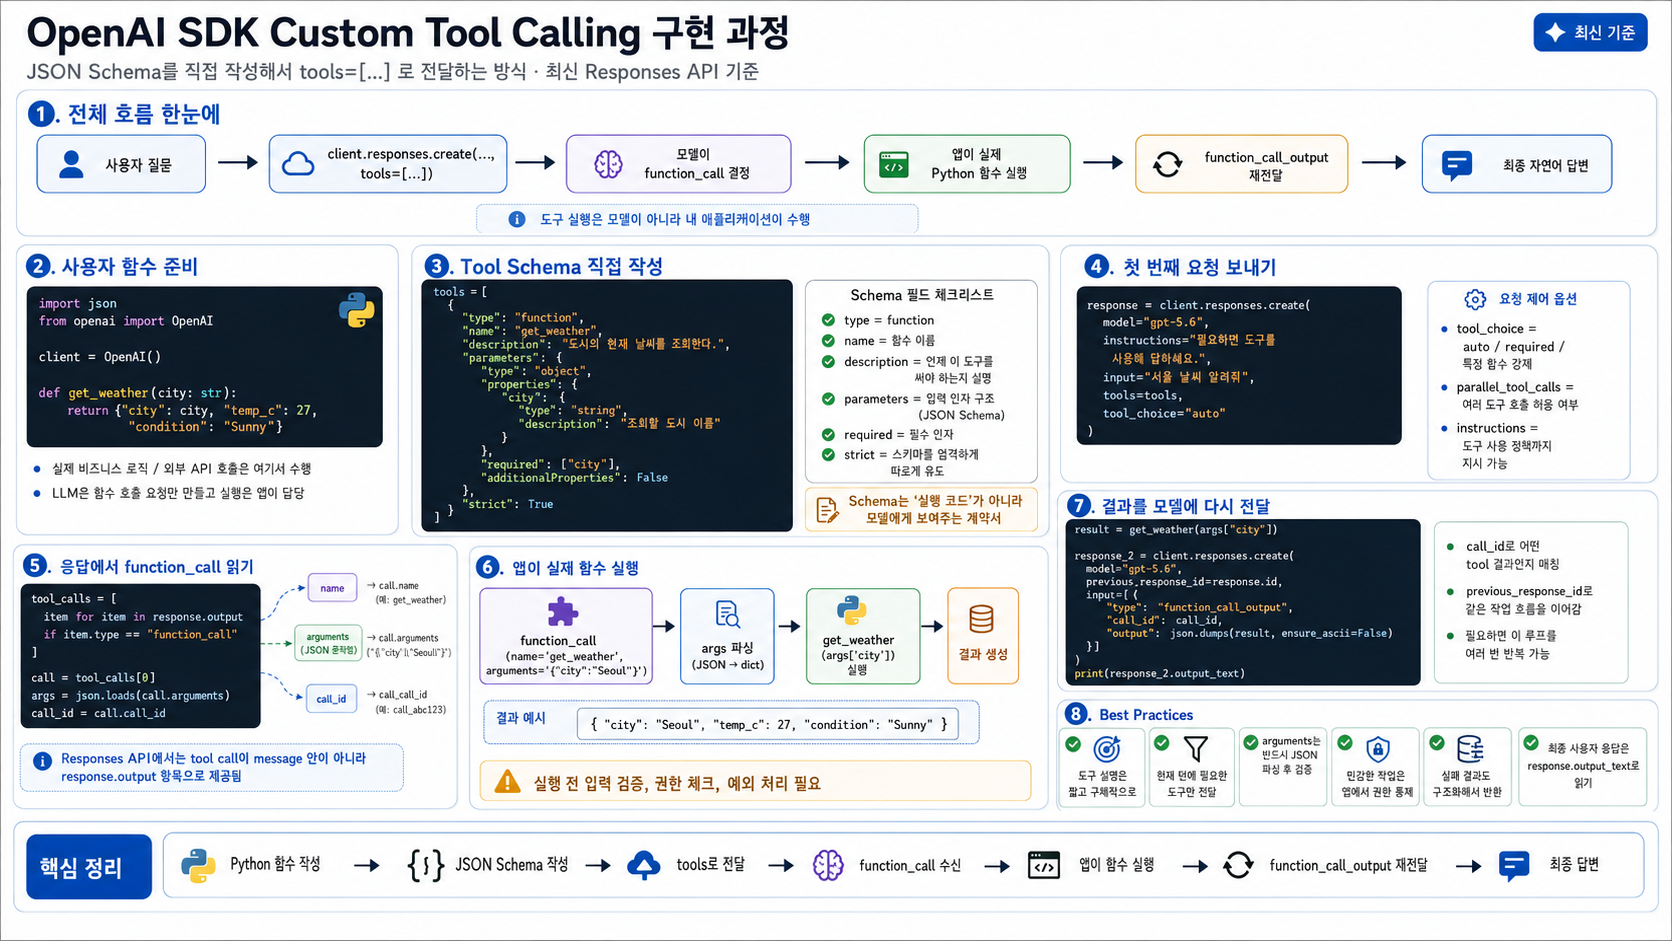

1. Python 함수를 작성하는데 반환값은 JSON으로 직렬화 가능한 dict 형태여야 함
2. 함수를 모델이 "보고 판단"할 수 있도록 JSON Schema로 노출
3. client.responses.create(model=..., instructions=..., input=질문, tools=툴 정보 리스트) 호출

In [2]:
import datetime
import json
from openai import OpenAI

# 1. 실제 실행될 파이썬 함수(Tool) 정의
def get_current_time() -> str:
    """현재 시스템 시간을 구하는 함수"""
    now = datetime.datetime.now()
    return json.dumps({"current_time": now.strftime("%Y-%m-%d %H:%M:%S")})

# 툴을 쉽게 매핑하기 위한 딕셔너리
available_tools = {
    "get_current_time": get_current_time
}

# 2. OpenAI 모델에게 전달할 Tool의 명세(Schema) 정의
tools_specification = [
    {
        "type": "function",
        "name": "get_current_time",
        "description": "사용자가 현재 시간, 오늘 날짜, 지금 시각 등을 물어볼 때 실시간 시스템 정보를 가져옵니다.",
        "parameters": {
            "type": "object",
            "properties": {} # 전달할 인자(Argument)가 없으므로 비워둡니다.
        }
    }
]

In [3]:
def main():
    # SDK가 환경 변수(OPENAI_API_KEY)를 자동으로 인식합니다.
    client = OpenAI()

    # 입력 데이터를 축적할 리스트 생성 (Responses API의 대화 상태 저장 방식)
    input_history = [
        {"role": "user", "content": "지금 몇 시야? 그리고 오늘 날짜도 알려줘."}
    ]

    print(f"사용자 질문: {input_history[0]['content']}\n")
    print("--- AI Agent Loop 시작 ---")

    # 3. 툴 실행 루프 (모델이 더 이상 툴을 호출하지 않고 최종 답변을 낼 때까지 반복)
    while True:
        response = client.responses.create(
            model="gpt-4o-mini",
            instructions="당신은 친절한 어시스턴트입니다. 정보를 답변할 때 필요하다면 제공된 도구를 적극적으로 사용하세요.",
            input=input_history,
            tools=tools_specification
        )

        # 모델이 생성한 출력 목록을 다음 루프의 컨텍스트에 누적 (.output에는 text나 function_call 등이 담김)
        input_history += response.output

        # 이번 턴에 모델이 툴 호출(function_call)을 요청했는지 확인
        has_tool_call = False

        print(response.output)
        
        for item in response.output:
            if item.type == "function_call":
                has_tool_call = True
                tool_name = item.name
                tool_call_id = item.call_id
                
                print(f"[AI 요청]: 툴 '{tool_name}' 실행이 필요합니다. (Call ID: {tool_call_id})")

                # 실제 파이썬 함수 매칭 및 실행
                if tool_name in available_tools:
                    tool_function = available_tools[tool_name]
                    tool_result = tool_function()
                    print(f"[툴 실행 결과]: {tool_result}")

                    #Responses API 형식에 맞춰 실행 결과를 input_history에 추가
                    input_history.append({
                        "type": "function_call_output",
                        "call_id": tool_call_id,
                        "output": tool_result
                    })
                else:
                    print(f"에러: {tool_name} 이라는 도구를 찾을 수 없습니다.")

        # 모델이 더 이상 툴을 호출하지 않았다면, 최종 자연어 답변이 완성된 것이므로 루프 종료
        if not has_tool_call:
            print("\n--- AI Agent Loop 종료 ---")
            # Responses API 전용 편리한 텍스트 추출 속성 사용
            print(f"\n최종 AI 답변:\n{response.output_text}")
            break

if __name__ == "__main__":
    main()

사용자 질문: 지금 몇 시야? 그리고 오늘 날짜도 알려줘.

--- AI Agent Loop 시작 ---
[ResponseFunctionToolCall(arguments='{}', call_id='call_IWvPmEfY9vRn3Ei6xmjwSrEb', name='get_current_time', type='function_call', id='fc_033211f97ed10fae006acc8a55261087d0b260f7628ae3e749', async_=None, caller=None, namespace=None, status='completed'), ResponseFunctionToolCall(arguments='{}', call_id='call_tnACkFA6umFXDeQYwnexdvoo', name='get_current_time', type='function_call', id='fc_033211f97ed10fae006acc8a55262087d08e9e51b8f1649078', async_=None, caller=None, namespace=None, status='completed')]
[AI 요청]: 툴 'get_current_time' 실행이 필요합니다. (Call ID: call_IWvPmEfY9vRn3Ei6xmjwSrEb)
[툴 실행 결과]: {"current_time": "2026-10-12 16:20:53"}
[AI 요청]: 툴 'get_current_time' 실행이 필요합니다. (Call ID: call_tnACkFA6umFXDeQYwnexdvoo)
[툴 실행 결과]: {"current_time": "2026-10-12 16:20:53"}
[ResponseOutputMessage(id='msg_033211f97ed10fae006acc8a5669d487d09638c206034c77ff', content=[ResponseOutputText(annotations=[], text='현재 시간은 16:20:53입니다. 오늘 날짜는 2026년 10월

**📝 정리** — 도구를 주니 모델이 `get_current_time`을 **두 번** 요청했다(시간 1번, 날짜 1번, 둘 다 인자 없음). 한 응답에 도구 호출 여러 개가 들어올 수 있어서 `for item in response.output`으로 하나씩 실행한다. 결과는 `function_call_output` + 같은 `call_id`로 대화 기록에 붙여서 다시 보내고, 모델이 더 이상 도구를 요청하지 않을 때 루프를 끝낸다.

![Tool을 처리하는내부구조2.png](<attachment:Tool을 처리하는내부구조2.png>)
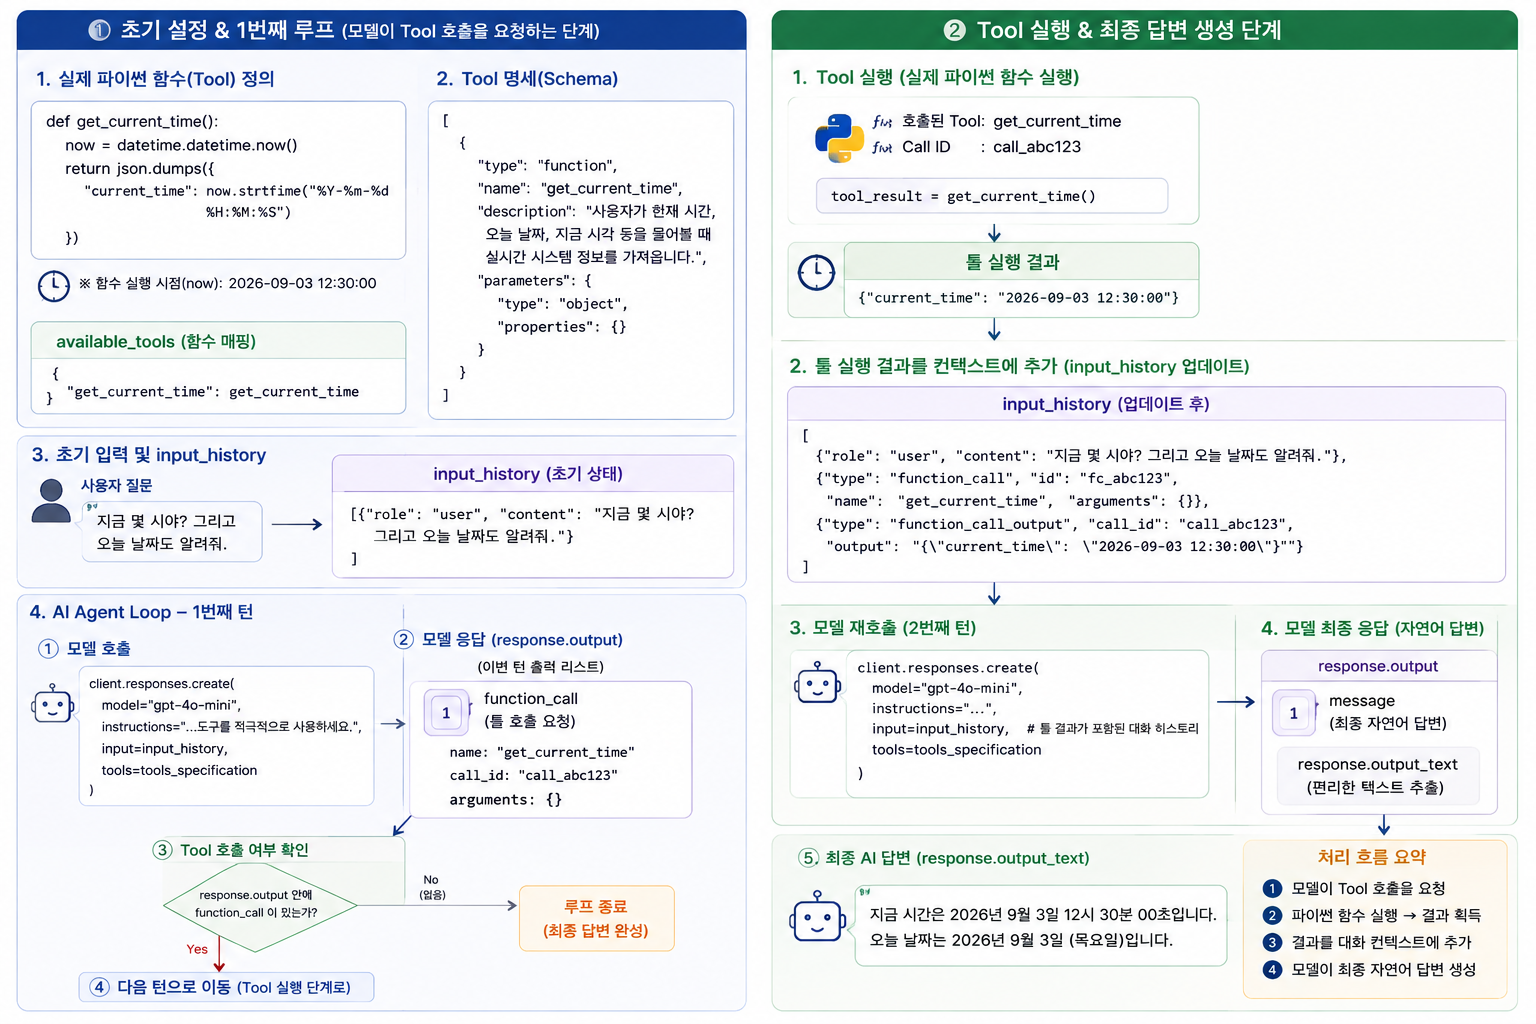

In [4]:
from openai import OpenAI

client = OpenAI()
# 최신 Responses API 호출 방식
response = client.responses.create(
    model="gpt-4o-mini",    
    input="지금 서울 날씨 어때?",
    max_output_tokens=500,
    temperature=0.7
)
print(response.output_text)

현재 서울의 날씨 정보를 제공할 수는 없지만, 서울의 날씨를 확인하고 싶다면 기상청 웹사이트나 날씨 앱을 이용해 최신 정보를 확인해 보세요! 필요하면 날씨에 관한 일반적인 정보를 알려드릴 수 있습니다.


In [5]:
from openai import OpenAI
import requests

# 1. 실제 날씨 정보를 API로 읽어오는 파이썬 함수
def get_current_weather(location: str) -> str:
    """
    지정된 도시(location)의 실시간 날씨 정보를 오픈 API에서 가져옵니다.
    """
    try:
        # wttr.in은 전 세계 도시명을 기반으로 날씨 데이터를 JSON으로 리턴하는 무료 오픈 서비스입니다.
        # ?format=j1 옵션을 주면 상세한 실시간 날씨 JSON 데이터를 얻을 수 있습니다.
        url = f"https://wttr.in/{location}?format=j1"
        response = requests.get(url, timeout=5)
        
        if response.status_code == 200:
            data = response.json()
            # 가장 최신 실시간 날씨 데이터 가공
            current_condition = data['current_condition'][0]
            temp_c = current_condition['temp_C']         # 현재 기온 (섭씨)
            weather_desc = current_condition['lang_ko'][0]['value'] if 'lang_ko' in current_condition else current_condition['weatherDesc'][0]['value'] # 날씨 상태 설명
            humidity = current_condition['humidity']       # 습도
            
            return json.dumps({
                "location": location,
                "temperature_celsius": f"{temp_c}°C",
                "condition": weather_desc,
                "humidity": f"{humidity}%"
            }, ensure_ascii=False)
        else:
            return json.dumps({"error": f"도시 '{location}'의 날씨 정보를 찾을 수 없습니다."})
            
    except Exception as e:
        return json.dumps({"error": f"날씨 정보를 가져오는 중 오류 발생: {str(e)}"})

# 함수 매핑 딕셔너리
AVAILABLE_TOOLS = {
    "get_current_weather": get_current_weather
}


# 2. OpenAI 규격에 맞춘 날씨 툴 명세 (인자값 구조 정의)
TOOLS_SPECIFICATION = [
    {
        "type": "function",
        "name": "get_current_weather",
        "description": "특정 도시나 국가명을 입력받아 실시간 날씨, 기온, 습도 정보를 조회합니다.",
        "parameters": {
            "type": "object",
            "properties": {
                # 💡 모델이 추출해야 할 변수(location)의 스펙을 정의합니다.
                "location": {
                    "type": "string",
                    "description": "날씨를 조회할 영문 도시명 (예: 'Seoul', 'Tokyo', 'London', 'New York')"
                }
            },
            "required": ["location"] # 이 인자값은 필수임을 명시
        }
    }
]

In [6]:
# 3. 메인 에이전트 실행 루프
def main():
    client = OpenAI() # 환경변수 OPENAI_API_KEY 자동 연동

    # 질문 예시 (한국어로 질문해도 모델이 인자값은 영어 도시명으로 알아서 변환해 줍니다)
    input_history = [
        {"role": "user", "content": "지금 서울 날씨 어때? 그리고 런던 날씨도 같이 확인해줘."}
    ]

    print(f"💬 사용자 질문: {input_history[0]['content']}\n")
    print("🤖 Agent Loop 가동 시작...")

    while True:
        response = client.responses.create(
            model="gpt-4o-mini",
            instructions="당신은 기상 캐스터 어시스턴트입니다. 제공된 도구를 사용해 실시간 정보를 얻어 사용자에게 친절하게 안내하세요.",
            input=input_history,
            tools=TOOLS_SPECIFICATION
        )

        # 모델 응답 결과 누적
        input_history += response.output
        has_tool_call = False

        for item in response.output:
            if item.type == "function_call":
                has_tool_call = True
                tool_name = item.name
                tool_call_id = item.call_id
                
                # 💡 핵심: 모델이 사용자 문장에서 지능적으로 발라낸 arguments(인자값)를 파싱합니다.
                # 예: {"location": "Seoul"}
                tool_args = json.loads(item.arguments) if hasattr(item, 'arguments') and item.arguments else {}
                
                print(f"👉 [AI 요청]: 툴 '{tool_name}' 실행 필요 (매개변수: {tool_args})")

                if tool_name in AVAILABLE_TOOLS:
                    tool_func = AVAILABLE_TOOLS[tool_name]

                    # 💡 딕셔너리 언패킹(**tool_args)을 통해 location='Seoul' 형태로 함수에 인자를 주입합니다.
                    tool_result = tool_func(**tool_args)
                    print(f"   [실행 완료]: 실시간 데이터 가져옴 -> {tool_result}")

                    # 결과값을 에이전트 대화 기록에 백업
                    input_history.append({
                        "type": "function_call_output",
                        "call_id": tool_call_id,
                        "output": tool_result
                    })

        # 더 이상 호출할 도구가 없다면 자연어 답변을 완성하고 루프 탈출
        if not has_tool_call:
            print("\n🤖 Agent Loop 종료.")
            print(f"\n✨ 최종 AI 답변:\n{response.output_text}")
            break

if __name__ == "__main__":
    main()

💬 사용자 질문: 지금 서울 날씨 어때? 그리고 런던 날씨도 같이 확인해줘.

🤖 Agent Loop 가동 시작...
👉 [AI 요청]: 툴 'get_current_weather' 실행 필요 (매개변수: {'location': 'Seoul'})
   [실행 완료]: 실시간 데이터 가져옴 -> {"location": "Seoul", "temperature_celsius": "27°C", "condition": "Patchy rain nearby", "humidity": "48%"}
👉 [AI 요청]: 툴 'get_current_weather' 실행 필요 (매개변수: {'location': 'London'})
   [실행 완료]: 실시간 데이터 가져옴 -> {"location": "London", "temperature_celsius": "14°C", "condition": "Overcast ", "humidity": "73%"}

🤖 Agent Loop 종료.

✨ 최종 AI 답변:
현재 서울의 날씨는 다음과 같습니다:
- **온도**: 27°C
- **상태**: 이곳 근처에서 가끔 비가 내리고 있습니다.
- **습도**: 48%

런던의 날씨는 다음과 같습니다:
- **온도**: 14°C
- **상태**: 흐림
- **습도**: 73%

두 도시 모두 기온과 습도가 많이 다르니 참고하세요!


**📝 정리** — 질문 하나에 서울·런던 두 도시가 있어서 모델이 `get_current_weather`를 `{'location': 'Seoul'}`, `{'location': 'London'}`로 두 번 요청했다. 한국어 질문이지만 도구 설명에 '영문 도시명'이라고 적어 둔 대로 영어로 바꿔서 넘겼다. 날씨 설명은 영어(`Patchy rain nearby`, `Overcast`)로 왔고 최종 답변에서 모델이 한국어로 옮겼다. 코드는 `lang_ko` 필드가 있으면 한국어 설명을 쓰도록 되어 있지만, 요청 URL에 언어 옵션이 없어서 영어 설명이 쓰였다. (이 셀은 앞 셀에서 import한 `json`을 그대로 쓴다)

오늘 실습은 여기까지. 이후 내용(Tool Schema 작성 원칙, 빌트인 툴, MCP 툴)은 다음 수업에서 이어진다.

## 🔁 복습 질문

<details>
<summary>1. 모델이 서울·런던 날씨 질문에 도구를 어떻게 요청했나?</summary>

`get_current_weather`를 `Seoul`, `London` 인자로 두 번 요청했다 (병렬 호출).
</details>

<details>
<summary>2. 한국어 질문인데 영문 도시명으로 인자를 채운 이유는?</summary>

도구 명세의 설명에 '영문 도시명'이라고 적어 두었기 때문이다. 모델은 명세를 따른다.
</details>
